# Logical magic states: ideal local simulation

We model the four-qubit H-state and five-qubit tetrahedral-state candidates from
the project plan. The output is an encoded data block; syndrome measurements
leave it available for subsequent operations. Only analysis copies are measured
destructively. There is no IBM service connection or noisy performance claim.

Use the **Python (quantum-jax)** kernel. B2_ED means syndrome screening, not a
claim of fault-tolerant preparation. B2_BK is a known five-copy projection with
ideal checks; its bare check circuit also needs a circuit-fault audit.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import qiskit, qiskit_aer
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'logical_magic').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'logical_magic').exists(), 'Open this notebook from the project.'
sys.path.insert(0, str(ROOT / 'src'))
from logical_magic import CODES, build_preparation, exact_result, magic_state
from logical_magic.simulation import estimate_fidelity, storage_fault_audit, circuit_fault_audit

print('Qiskit:', qiskit.__version__, ' Aer:', qiskit_aer.__version__)
print('Workspace:', ROOT)

Qiskit: 2.4.1  Aer: 0.17.2
Workspace: /Users/runzhemo/Desktop/Zhuang_group/hackathon


## 1. Mathematical reference

All Pauli labels use Qiskit ordering: the rightmost character acts on q0. The
logical input is on q0. For the four-qubit code,

$$|0_L\rangle=(|0000\rangle+|1111\rangle)/\sqrt2,\quad
|1_L\rangle=(|0011\rangle+|1100\rangle)/\sqrt2.$$

The H target is $\cos(\pi/8)|0_L\rangle+\sin(\pi/8)|1_L\rangle$.
The five-qubit tetrahedral target has logical Bloch vector $(1,1,1)/\sqrt3$;
it is different from the equatorial pi/8-gate resource state.
The reference basis below comes from algebraic projectors, independent of the
gate-level encoder.

In [2]:
for model in CODES.values():
    print(model.name, f'[[{model.n},1,{model.distance}]]')
    print('  stabilizers:', model.stabilizers)
    print('  logical X/Z:', model.logical_x, model.logical_z)
    print('  independently computed distance:', model.computed_distance())
    print('  codespace rank:', round(np.trace(model.projector).real))
    assert np.allclose(model.basis.conj().T @ model.basis, np.eye(2))

four [[4,1,2]]
  stabilizers: ('XXXX', 'IIZZ', 'ZZII')
  logical X/Z: IIXX IZIZ
  independently computed distance: 2
  codespace rank: 2
five [[5,1,3]]
  stabilizers: ('XZZXI', 'IXZZX', 'XIXZZ', 'ZXIXZ')
  logical X/Z: XXXXX ZZZZZ
  independently computed distance: 3
  codespace rank: 2


## 2. A reusable preparation circuit

B1 prepares a physical magic state and encodes it. B2_ED then measures each
stabilizer using a fresh ancilla. Acceptance is the all-zero syndrome. The
following preparation circuit measures only ancillas.

In [3]:
primary = build_preparation(CODES['four'], 'B2_ED')
print(primary.measured().draw(output='text', fold=110))
print(primary.resources())

            ┌─────────┐     ┌───┐     ┌───┐                                           
       q_0: ┤ Ry(π/4) ├──■──┤ X ├─────┤ X ├──────■────────────────────────────────────
            └─────────┘┌─┴─┐└─┬─┘┌───┐└─┬─┘┌───┐ │                                    
       q_1: ───────────┤ X ├──┼──┤ X ├──┼──┤ X ├─┼───────■────────────────────────────
               ┌───┐   └───┘  │  └─┬─┘  │  └─┬─┘ │ ┌───┐ │                            
       q_2: ───┤ H ├─────■────■────■────┼────┼───┼─┤ X ├─┼───────■────────────────────
               └───┘   ┌─┴─┐            │    │   │ └─┬─┘ │ ┌───┐ │                    
       q_3: ───────────┤ X ├────────────┼────┼───┼───┼───┼─┤ X ├─┼───────■────────────
               ┌───┐   └───┘            │    │   │   │   │ └─┬─┘ │ ┌───┐ │      ┌─┐   
       q_4: ───┤ H ├────────────────────■────■───┼───■───┼───■───┼─┤ H ├─┼──────┤M├───
               ├───┤                             │       │ ┌───┐ │ └┬─┬┘ │      └╥┘   
       q_5: ───┤ H ├───────────────────────

## 3. Exact ideal baselines

Fidelity is $\langle\psi_L|\rho_{\mathrm{accepted}}|\psi_L\rangle$ and acceptance is
the probability of the physically recorded all-zero syndrome. No additional
projection or decoder is used to improve the reported state.

The BK row prepares five **antipodal** tetrahedral states. The projection reverses
the pole, leaving the same positive logical target as B1. Its nontrivial ideal
acceptance of 1/6 is a useful check of normalization and postselection.

In [4]:
table = ['| Model / strategy | Fidelity | Acceptance | 2q gates | Total qubits |',
         '|---|---:|---:|---:|---:|']
for model in CODES.values():
    strategies = ['B0', 'B1', 'B2_ED'] + (['B2_BK'] if model.name == 'five' else [])
    for strategy in strategies:
        result = exact_result(build_preparation(model, strategy))
        assert np.isclose(result['fidelity'], 1)
        expected = 1/6 if strategy == 'B2_BK' else 1
        assert np.isclose(result['acceptance'], expected)
        table.append(f"| {model.name}/{strategy} | {result['fidelity']:.9f} | {result['acceptance']:.9f} | {result['resources']['two_qubit_gates']} | {result['resources']['total_qubits']} |")
display(Markdown('\n'.join(table)))

| Model / strategy | Fidelity | Acceptance | 2q gates | Total qubits |
|---|---:|---:|---:|---:|
| four/B0 | 1.000000000 | 1.000000000 | 0 | 1 |
| four/B1 | 1.000000000 | 1.000000000 | 4 | 4 |
| four/B2_ED | 1.000000000 | 1.000000000 | 12 | 7 |
| five/B0 | 1.000000000 | 1.000000000 | 0 | 1 |
| five/B1 | 1.000000000 | 1.000000000 | 12 | 5 |
| five/B2_ED | 1.000000000 | 1.000000000 | 28 | 9 |
| five/B2_BK | 1.000000000 | 0.166666667 | 16 | 9 |

## 4. Finite-shot physical fidelity

For possible codespace leakage, the observable is
$P(I+r_xX_L+r_yY_L+r_zZ_L)/2$, not just the logical Bloch overlap.
We measure its physical Pauli expansion on separately prepared copies, always
using the same syndrome-acceptance rule. Including P in this observable does not
physically project or purify the delivered output.

Linear estimates can lie slightly outside [0,1]; they remain unclipped. The
standard error is a plug-in shot estimate. A conservative Hoeffding interval is
also returned, and acceptance gets its own Wilson interval.

In [5]:
sampled = estimate_fidelity(primary, shots=8192, seed=20261014)
for key in ['fidelity_estimate', 'standard_error_plugin',
            'fidelity_conservative_95_interval', 'acceptance_estimate',
            'acceptance_wilson_95_interval', 'measurement_settings', 'total_shots']:
    print(f'{key}: {sampled[key]}')
print('First Pauli setting with raw counts:', sampled['terms'][0])

fidelity_estimate: 1.0011766050127426
standard_error_plugin: 0.0013776995674205643
fidelity_conservative_95_interval: [0.9544560772591191, 1.0]
acceptance_estimate: 1.0
acceptance_wilson_95_interval: [0.9995312917117791, 1.0]
measurement_settings: 23
total_shots: 196608
First Pauli setting with raw counts: {'pauli': 'IIXX', 'coefficient': 0.04419417382415921, 'accepted': 8192, 'expectation': 0.714111328125, 'counts': {'1110 000': 297, '0001 000': 305, '0011 000': 1729, '0010 000': 303, '0000 000': 1801, '1100 000': 1698, '1101 000': 266, '1111 000': 1793}}


## 5. Storage-error detection versus preparation faults

Single-qubit Pauli errors **after encoding and before ideal checks** are all
detected. This does not imply that faults in preparation and verification are
detected. The full audit includes all 15 nonidentity two-qubit Paulis after each
two-qubit gate, not only independent one-qubit faults.

In [6]:
for model in CODES.values():
    rows = storage_fault_audit(build_preparation(model, 'B2_ED'))
    rejected = sum(r['acceptance'] == 0 for r in rows)
    print(f'{model.name}: {rejected}/{len(rows)} single data Pauli errors rejected')
    assert rejected == len(rows)

faults = circuit_fault_audit(primary)
counterexample = next(r for r in faults if r['stage'] == 'magic_input' and r['pauli'] == 'Y')
print('Counterexample: Y immediately after physical H-state preparation')
display(counterexample)
assert np.isclose(counterexample['acceptance'], 1)
assert np.isclose(counterexample['codespace_population'], 1)
assert np.isclose(counterexample['fidelity'], 0)

four: 12/12 single data Pauli errors rejected
five: 15/15 single data Pauli errors rejected
Counterexample: Y immediately after physical H-state preparation


{'stage': 'magic_input',
 'location': 0,
 'gate': 'ry',
 'qubits': '0',
 'pauli': 'Y',
 'category': 'accepted_harmful',
 'acceptance': 0.9999999999999987,
 'fidelity': 3.340608130839606e-33,
 'codespace_population': 1.0,
 'logical_bloch': [-0.7071067811865475, 0.0, -0.7071067811865477],
 'attempts_per_accept': 1.0000000000000013}

## 6. Restricted code-capability check: a single storage Pauli

**This is a code/decoder unit test, not a realistic model of the whole preparation
circuit.** Its successful five-qubit result does not extend to faults occurring
during encoding or syndrome extraction. Section 7 tests a few such locations.

Inject exactly one Pauli **after encoding and before syndrome extraction**, at
each data-qubit location. Also run an identity/no-error control. Preparation,
syndrome measurements, and correction gates are otherwise ideal. This tests
storage-error correction, not faults during preparation or recovery.

The decoder gets **only the measured syndrome**, not the injected Pauli or its
location. A fixed lookup table selects a Pauli recovery using Qiskit's
`if_test((syndrome_register, value))` classical feed-forward. All outcomes are
kept: this is active correction with no zero-syndrome postselection. Data qubits
remain unmeasured and available for reuse.

For the [[5,1,3]] code the 15 single-Pauli errors have 15 distinct nonzero
syndromes. The [[4,1,2]] code detects all single-Pauli errors but cannot correct
an arbitrary one at an unknown location. For an ambiguous syndrome, the example
decoder chooses the first representative in q0, q1, ... order, then X/Y/Z.
This convention is fixed before the sweep, not optimized for the injected fault.

Each row below shows the full circuit's syndrome counts (256 shots), physical
target fidelity before and after recovery, and whether the residual operator
is identity up to phase **on the entire logical codespace**. The final density
matrix comes from the Aer simulation of measurement and conditional gates;
its fidelity is an exact simulator diagnostic, not a finite-shot tomography
estimate. Every shot has the same syndrome in this ideal experiment.

In [7]:
from logical_magic.error_correction import (
    single_pauli_experiment, syndrome_candidates, recovery_table,
    residual_logical_operator, corrects_codespace, correction_circuit,
)

pauli_sweeps = {name: single_pauli_experiment(model, shots=256, seed=20261014)
                for name, model in CODES.items()}
pauli_output = ROOT / 'results' / 'single_pauli_errors.json'
pauli_output.parent.mkdir(exist_ok=True)
pauli_output.write_text(json.dumps(pauli_sweeps, indent=2) + '\n')

for name, sweep in pauli_sweeps.items():
    display(Markdown(f"### {name}: {sweep['detected_errors']}/{sweep['total_errors']} detected; "
                     f"{sweep['corrected_errors']}/{sweep['total_errors']} corrected by this decoder"))
    lines = ['| Injected error | Pauli label | Measured syndrome | Shots | Recovery | F before | F after | Restores any logical state? |',
             '|---|---|---|---:|---|---:|---:|---|']
    for row in sweep['rows']:
        error_name = 'none (control)' if row['qubit'] is None else f"{row['pauli']} on q{row['qubit']}"
        measured_shots = row['syndrome_counts'][row['syndrome']]
        restored = 'yes' if row['corrects_arbitrary_logical_state'] else 'no'
        lines.append(f"| {error_name} | {row['label']} | {row['syndrome']} | {measured_shots} | {row['recovery']} | {row['fidelity_before']:.6f} | {row['fidelity_after']:.6f} | {restored} |")
    display(Markdown('\n'.join(lines)))

assert pauli_sweeps['five']['detected_errors'] == pauli_sweeps['five']['corrected_errors'] == 15
assert pauli_sweeps['four']['detected_errors'] == 12
assert pauli_sweeps['four']['corrected_errors'] == 6
print('Saved every error, no-error control, and raw syndrome counts to:', pauli_output)

### four: 12/12 detected; 6/12 corrected by this decoder

| Injected error | Pauli label | Measured syndrome | Shots | Recovery | F before | F after | Restores any logical state? |
|---|---|---|---:|---|---:|---:|---|
| none (control) | IIII | 000 | 256 | IIII | 1.000000 | 1.000000 | yes |
| X on q0 | IIIX | 010 | 256 | IIIX | 0.000000 | 1.000000 | yes |
| Y on q0 | IIIY | 011 | 256 | IIIY | 0.000000 | 1.000000 | yes |
| Z on q0 | IIIZ | 001 | 256 | IIIZ | 0.000000 | 1.000000 | yes |
| X on q1 | IIXI | 010 | 256 | IIIX | 0.000000 | 0.500000 | no |
| Y on q1 | IIYI | 011 | 256 | IIIY | 0.000000 | 0.500000 | no |
| Z on q1 | IIZI | 001 | 256 | IIIZ | 0.000000 | 1.000000 | yes |
| X on q2 | IXII | 100 | 256 | IXII | 0.000000 | 1.000000 | yes |
| Y on q2 | IYII | 101 | 256 | IYII | 0.000000 | 1.000000 | yes |
| Z on q2 | IZII | 001 | 256 | IIIZ | 0.000000 | 0.500000 | no |
| X on q3 | XIII | 100 | 256 | IXII | 0.000000 | 0.500000 | no |
| Y on q3 | YIII | 101 | 256 | IYII | 0.000000 | 0.500000 | no |
| Z on q3 | ZIII | 001 | 256 | IIIZ | 0.000000 | 0.500000 | no |

### five: 15/15 detected; 15/15 corrected by this decoder

| Injected error | Pauli label | Measured syndrome | Shots | Recovery | F before | F after | Restores any logical state? |
|---|---|---|---:|---|---:|---:|---|
| none (control) | IIIII | 0000 | 256 | IIIII | 1.000000 | 1.000000 | yes |
| X on q0 | IIIIX | 1100 | 256 | IIIIX | 0.000000 | 1.000000 | yes |
| Y on q0 | IIIIY | 1110 | 256 | IIIIY | 0.000000 | 1.000000 | yes |
| Z on q0 | IIIIZ | 0010 | 256 | IIIIZ | 0.000000 | 1.000000 | yes |
| X on q1 | IIIXI | 0110 | 256 | IIIXI | 0.000000 | 1.000000 | yes |
| Y on q1 | IIIYI | 1111 | 256 | IIIYI | 0.000000 | 1.000000 | yes |
| Z on q1 | IIIZI | 1001 | 256 | IIIZI | 0.000000 | 1.000000 | yes |
| X on q2 | IIXII | 0011 | 256 | IIXII | 0.000000 | 1.000000 | yes |
| Y on q2 | IIYII | 0111 | 256 | IIYII | 0.000000 | 1.000000 | yes |
| Z on q2 | IIZII | 0100 | 256 | IIZII | 0.000000 | 1.000000 | yes |
| X on q3 | IXIII | 0001 | 256 | IXIII | 0.000000 | 1.000000 | yes |
| Y on q3 | IYIII | 1011 | 256 | IYIII | 0.000000 | 1.000000 | yes |
| Z on q3 | IZIII | 1010 | 256 | IZIII | 0.000000 | 1.000000 | yes |
| X on q4 | XIIII | 1000 | 256 | XIIII | 0.000000 | 1.000000 | yes |
| Y on q4 | YIIII | 1101 | 256 | YIIII | 0.000000 | 1.000000 | yes |
| Z on q4 | ZIIII | 0101 | 256 | ZIIII | 0.000000 | 1.000000 | yes |

Saved every error, no-error control, and raw syndrome counts to: /Users/runzhemo/Desktop/Zhuang_group/hackathon/results/single_pauli_errors.json


### Why four-qubit detection does not guarantee correction

The following table lists all errors sharing each four-qubit syndrome and the
decoder's fixed choice. A collision alone is not enough to prove failure:
errors that differ only by a stabilizer act identically on the codespace.
We therefore check the residual logical operator $V^\dagger R E V$, where V is
the encoding isometry. Successful recovery of an arbitrary logical state
requires this to be identity up to phase.

For example, X on q0 and X on q1 both give syndrome **010**, but their product
is $X_L$. Choosing q0's correction when the error was on q1 leaves a logical X.
For $|H_L\rangle$, the recovered fidelity is then
$|\langle H_L|X_L|H_L\rangle|^2=1/2$ even though the state is back in the
codespace. Z on q0 and Z on q1 are a benign collision because their product is
a stabilizer. Z on q0 and Z on q2 instead differ by $Z_L$.

The **6/12** count is the outcome of this particular deterministic decoder on
an unweighted list of injected errors; it is not a universal correction rate.
Knowing the error location would provide additional information, which this
experiment does not give the decoder.

In [8]:
model = CODES['four']
table = recovery_table(model)
lines = ['| Syndrome | Candidate errors (Qiskit labels) | Chosen recovery | Restores every candidate? |',
         '|---|---|---|---|']
for syndrome, candidates in syndrome_candidates(model).items():
    if int(syndrome, 2) == 0:
        continue
    works_for_all = all(corrects_codespace(residual_logical_operator(model, e, table[syndrome]))
                        for e in candidates)
    lines.append(f"| {syndrome} | {', '.join(candidates)} | {table[syndrome]} | {'yes' if works_for_all else 'no'} |")
display(Markdown('\n'.join(lines)))

print('Residual logical operator for error X on q1, recovery X on q0:')
display(np.real_if_close(residual_logical_operator(model, 'IIXI', 'IIIX')))

# This actual dynamic circuit can be inspected or reused; its data is not measured.
five_qubit_recovery_example = correction_circuit(CODES['five'], 'IIIIY')
print('Example: Y on q0 in the five-qubit code')
print('Classically conditioned recovery branches:', five_qubit_recovery_example.count_ops()['if_else'])

| Syndrome | Candidate errors (Qiskit labels) | Chosen recovery | Restores every candidate? |
|---|---|---|---|
| 010 | IIIX, IIXI | IIIX | no |
| 011 | IIIY, IIYI | IIIY | no |
| 001 | IIIZ, IIZI, IZII, ZIII | IIIZ | no |
| 100 | IXII, XIII | IXII | no |
| 101 | IYII, YIII | IYII | no |

Residual logical operator for error X on q1, recovery X on q0:


array([[0., 1.],
       [1., 0.]])

Example: Y on q0 in the five-qubit code
Classically conditioned recovery branches: 15


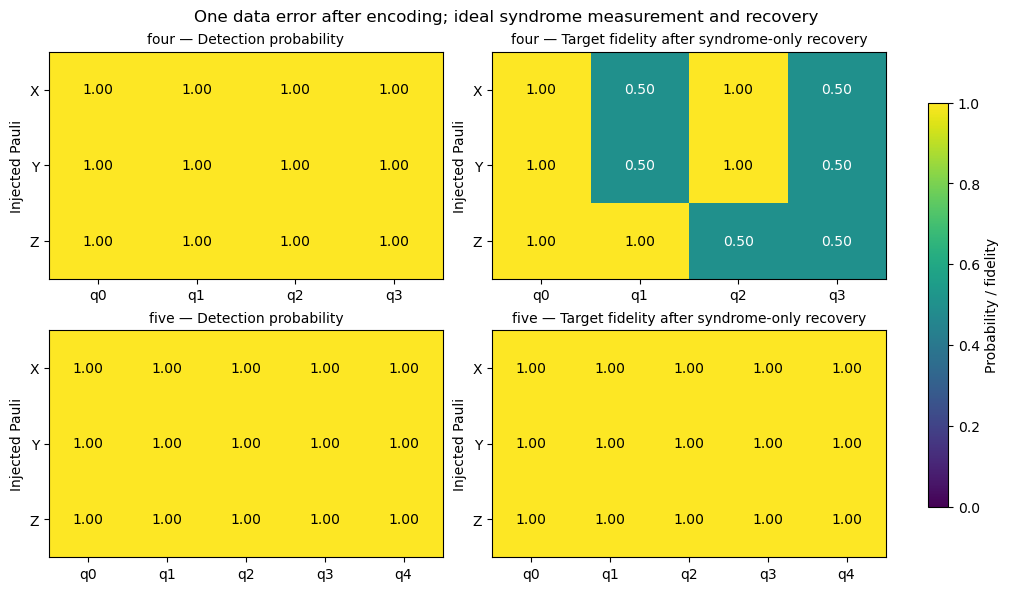

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 5.8), constrained_layout=True)
for i, (name, sweep) in enumerate(pauli_sweeps.items()):
    for j, (field, title) in enumerate([
        ('detection_probability', 'Detection probability'),
        ('fidelity_after', 'Target fidelity after syndrome-only recovery'),
    ]):
        values = np.zeros((3, CODES[name].n))
        for row in sweep['rows'][1:]:
            values['XYZ'.index(row['pauli']), row['qubit']] = row[field]
        ax = axes[i, j]
        im = ax.imshow(values, vmin=0, vmax=1, cmap='viridis', aspect='auto')
        ax.set_xticks(range(CODES[name].n), [f'q{k}' for k in range(CODES[name].n)])
        ax.set_yticks(range(3), list('XYZ'))
        ax.set_title(f'{name} — {title}', fontsize=10)
        ax.set_ylabel('Injected Pauli')
        for p in range(3):
            for q in range(CODES[name].n):
                ax.text(q, p, f'{values[p,q]:.2f}', ha='center', va='center',
                        color='black' if values[p,q] > .7 else 'white')
fig.colorbar(im, ax=axes, label='Probability / fidelity', shrink=.8)
fig.suptitle('One data error after encoding; ideal syndrome measurement and recovery')
fig.savefig(ROOT / 'results' / 'single_pauli_errors.png', dpi=180)
fig.savefig(ROOT / 'results' / 'single_pauli_errors.pdf')
plt.show()
plt.close(fig)

The five-qubit code restores the target and the entire logical qubit for
every tested single X/Y/Z error. The four-qubit code detects every tested error,
but its ambiguous syndromes prevent universal correction. All recovery outputs
in this sweep are in the codespace, so codespace population alone would miss
the four-qubit logical failures. Both no-error controls retain fidelity 1.
These statements assume perfect syndrome extraction and recovery; they do not
supersede the circuit-fault limitations in Section 5.

## 7. Representative faults at different circuit locations

The location restriction in Section 6 is useful for checking code distance and
decoder conventions, but insufficient for our preparation objective. A fault
during encoding can spread across data qubits; a syndrome-ancilla fault can
propagate through subsequent couplings; a wrong syndrome bit can cause a wrong
correction. A single physical fault need not remain a single-qubit error at the
end of the circuit. See the [IBM explanation of error propagation](https://quantum.cloud.ibm.com/learning/en/courses/foundations-of-quantum-error-correction/fault-tolerant-quantum-computing/controlling-error-propagation).

Here we try **a few fixed examples**, not a new exhaustive sweep:

1. No-error control and the previous post-encoding X0 example.
2. Y0 just after magic-state preparation, before encoding.
3. Z on the target of the first encoder CX, immediately after that gate.
4. X on the first syndrome ancilla after its second data coupling.
5. X0 after syndrome extraction, before ancilla readout.
6. A flip of recorded syndrome bit 0 without a data fault.

The decoder remains fixed and only sees the measured syndrome. There is no
postselection. Each circuit is simulated in Aer with actual measurement and
conditional recovery, and checked against an independent exact branch sum.
The Pauli insertion points are logical circuit locations, not a scheduled idle
noise model. These examples do not assign fault rates or establish exhaustive
protection guarantees.

We report the **actual delivered fidelity** and codespace population. A separate
column asks what fidelity would result from **one additional, hypothetical ideal
syndrome/recovery round**. This diagnostic is not part of the delivered state.
It distinguishes recoverable residual errors from failures that the same ideal
decoder cannot repair. In particular, a residual single data-qubit error can
lower physical target fidelity without itself constituting a logical failure.

In [10]:
from logical_magic.fault_examples import run_representative_examples

location_examples = {name: run_representative_examples(model, shots=256, seed=20261014)
                     for name, model in CODES.items()}
example_output = ROOT / 'results' / 'representative_fault_locations.json'
example_output.write_text(json.dumps(location_examples, indent=2) + '\n')

for name, experiment in location_examples.items():
    display(Markdown(f'### {name}: selected fault locations'))
    lines = ['| Insertion example | Recorded syndrome | F delivered | Codespace population | F after an extra ideal round (diagnostic) |',
             '|---|---|---:|---:|---:|']
    for row in experiment['rows']:
        if row['events'] > 1:
            continue  # The two-event recovery test is explained separately below.
        syndrome = ', '.join(row['syndrome_counts'])
        lines.append(f"| {row['description']} | {syndrome} | {abs(row['fidelity_after_recovery']):.6f} | {abs(row['codespace_after_recovery']):.6f} | {abs(row['fidelity_after_hypothetical_ideal_round']):.6f} |")
    display(Markdown('\n'.join(lines)))

print('Exact insertion indices, gate operands, syndrome counts, and results:', example_output)

### four: selected fault locations

| Insertion example | Recorded syndrome | F delivered | Codespace population | F after an extra ideal round (diagnostic) |
|---|---|---:|---:|---:|
| No error | 000 | 1.000000 | 1.000000 | 1.000000 |
| X on q0 after encoding (previous test) | 010 | 1.000000 | 1.000000 | 1.000000 |
| Y on q0 after magic preparation, before encoder | 000 | 0.000000 | 1.000000 | 0.000000 |
| Z on q1 after the first encoder CX | 000 | 0.500000 | 1.000000 | 0.500000 |
| X on ancilla q4 after check 0's second coupling | 000 | 0.500000 | 1.000000 | 0.500000 |
| X on q0 after extraction, before ancilla readout | 000 | 0.000000 | 0.000000 | 1.000000 |
| Flip recorded syndrome bit 0; no data fault | 001 | 0.000000 | 0.000000 | 1.000000 |

### five: selected fault locations

| Insertion example | Recorded syndrome | F delivered | Codespace population | F after an extra ideal round (diagnostic) |
|---|---|---:|---:|---:|
| No error | 0000 | 1.000000 | 1.000000 | 1.000000 |
| X on q0 after encoding (previous test) | 1100 | 1.000000 | 1.000000 | 1.000000 |
| Y on q0 after magic preparation, before encoder | 0000 | 0.333333 | 1.000000 | 0.333333 |
| Z on q2 after the first encoder CX | 0001 | 0.333333 | 1.000000 | 0.333333 |
| X on ancilla q5 after check 0's second coupling | 0010 | 0.333333 | 1.000000 | 0.333333 |
| X on q0 after extraction, before ancilla readout | 0000 | 0.000000 | 0.000000 | 1.000000 |
| Flip recorded syndrome bit 0; no data fault | 0001 | 0.000000 | 0.000000 | 1.000000 |

Exact insertion indices, gate operands, syndrome counts, and results: /Users/runzhemo/Desktop/Zhuang_group/hackathon/results/representative_fault_locations.json


### What these examples show

For the five-qubit code, the storage X0 is corrected with fidelity 1. Moving a
fault into the encoder (Z on the first CX target) or onto the syndrome ancilla
(X after its second coupling) instead leaves fidelity **1/3** after recovery.
The resulting state is in the codespace, and another perfect syndrome/recovery
round cannot restore it. A nonzero syndrome flag does not guarantee that the
storage-error lookup table has identified the right correction.

Y0 before encoding is another direct counterexample: encoding maps this to a
logical Y. The syndrome stays zero; the four-qubit H-state fidelity is 0 and
the five-qubit tetrahedral-state fidelity is 1/3. Stabilizer checks do not verify
the intended logical magic state.

The late X0 and recorded-bit flip instead leave a residual data error that the
extra ideal round repairs. Thus the distinction between a code's single-error
correction ability and a circuit's fault propagation is visible in the results.
These examples invalidate extending the Section 6 success claim to the whole
preparation circuit; they do not by themselves select a fault-tolerant replacement.

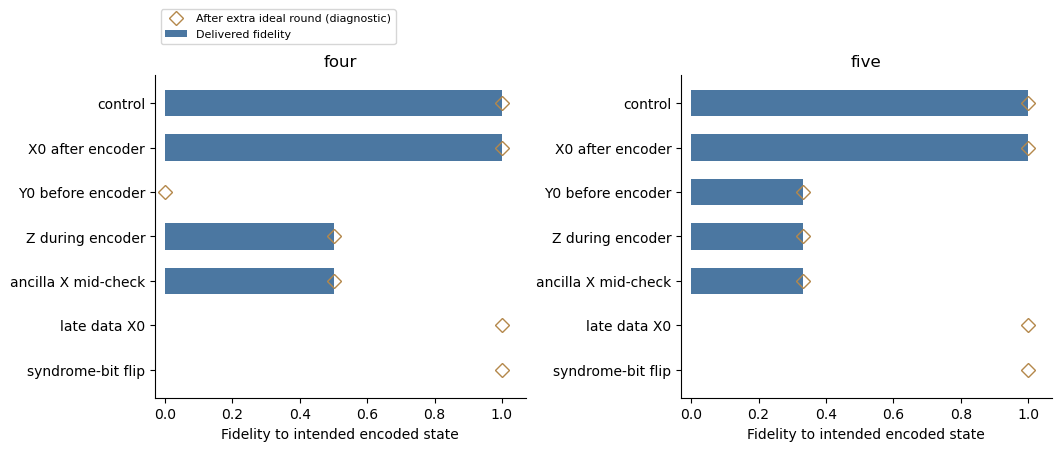

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
labels = ['control', 'X0 after encoder', 'Y0 before encoder', 'Z during encoder',
          'ancilla X mid-check', 'late data X0', 'syndrome-bit flip']
for ax, (name, experiment) in zip(axes, location_examples.items()):
    rows = [r for r in experiment['rows'] if r['events'] <= 1]
    y = np.arange(len(rows))
    ax.barh(y, [r['fidelity_after_recovery'] for r in rows], color='#4b77a1',
            height=.6, label='Delivered fidelity')
    ax.plot([r['fidelity_after_hypothetical_ideal_round'] for r in rows], y,
            'D', color='#b4884b', markerfacecolor='none', markersize=7,
            label='After extra ideal round (diagnostic)')
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set(xlim=(-.03, 1.07), xlabel='Fidelity to intended encoded state', title=name)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1.08), fontsize=8)
fig.savefig(ROOT / 'results' / 'representative_fault_locations.png', dpi=180)
fig.savefig(ROOT / 'results' / 'representative_fault_locations.pdf')
plt.show()
plt.close(fig)

### One separately labeled recovery-gate example

On a clean input the syndrome is zero and no nonidentity correction gate is
executed. To exercise an actual correction gate, this last example deliberately
combines a pre-existing storage X0 with a Z fault immediately after its recovery
gate. It has **two error events**, so it is not included among the one-fault
examples above. It shows the distinction between a faulty recovery operation
and an already faulty input; it is not evidence against a single-fault guarantee.

For both codes this example leaves delivered fidelity 0 and a residual error
that an extra ideal round repairs. Perfect recovery was an assumption in
Section 6, not an experimentally established property of its implementation.

In [12]:
for name, experiment in location_examples.items():
    row = next(r for r in experiment['rows'] if r['name'] == 'faulty_recovery')
    print(f"{name}: {row['events']} events; F delivered = {abs(row['fidelity_after_recovery']):.6f}; "
          f"F after hypothetical ideal round = {row['fidelity_after_hypothetical_ideal_round']:.6f}")

four: 2 events; F delivered = 0.000000; F after hypothetical ideal round = 1.000000
five: 2 events; F delivered = 0.000000; F after hypothetical ideal round = 1.000000


## 8. Saved comparison and next experiment

The plots below include all seven baselines and the full circuit-fault audit.
Fault counts are enumeration counts, not probabilities under a noise model.
The fidelity plot's error bars are 1.96 times the plug-in standard error.

For the next stage, reuse the builders with explicit gate/readout/idle noise,
and retain conditioning on **recorded** syndrome bits. Backend transpilation,
timing, and gate-fault propagation still require validation. No B3 optimization
can be selected from an ideal-fidelity tie.

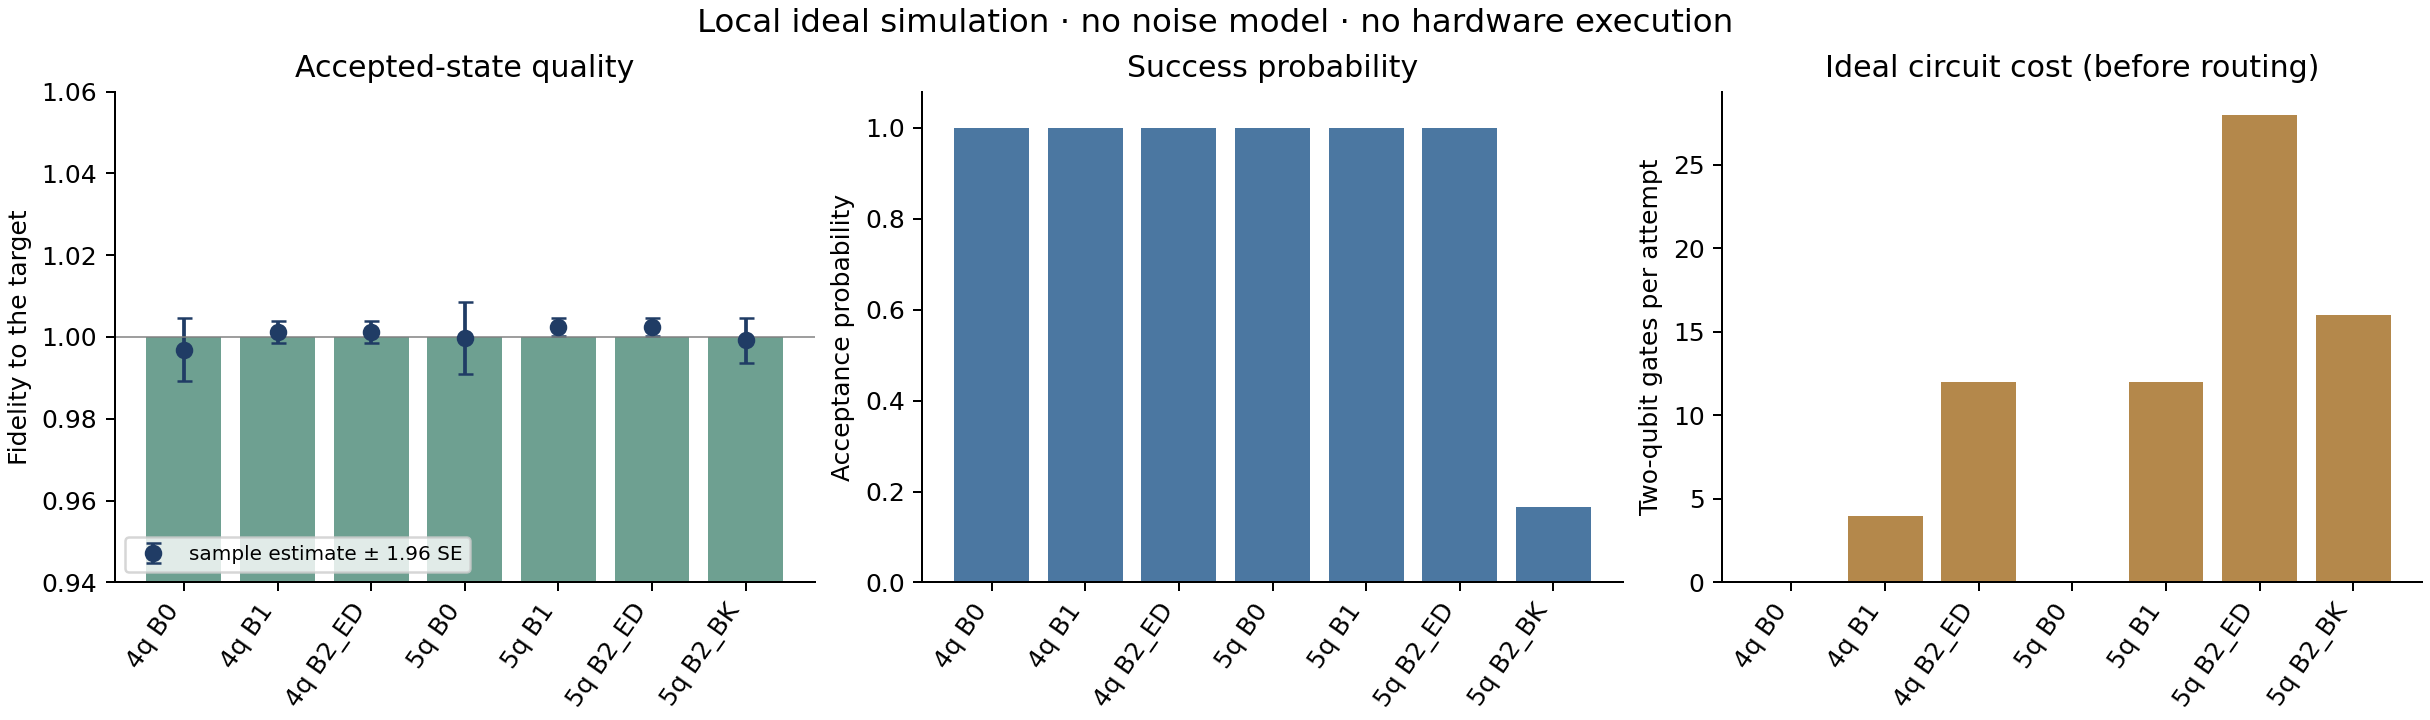

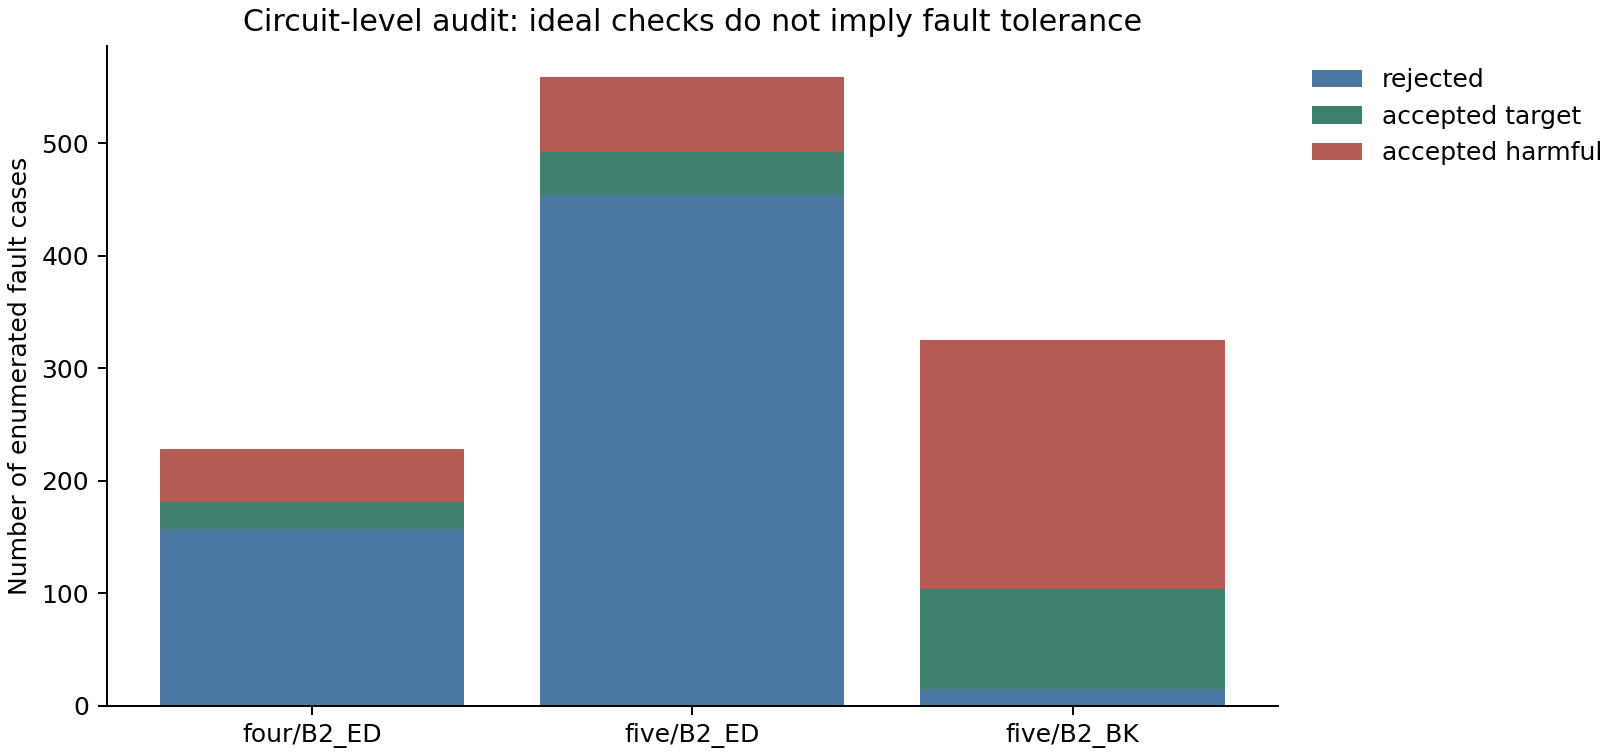

Detailed report: /Users/runzhemo/Desktop/Zhuang_group/hackathon/results/ideal/ideal_report.md


In [13]:
result_dir = ROOT / 'results' / 'ideal'
if not (result_dir / 'ideal_results.json').exists():
    import subprocess
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'run_ideal.py')], check=True)
display(Image(filename=str(result_dir / 'ideal_comparison.png')))
display(Image(filename=str(result_dir / 'fault_audit.png')))
print('Detailed report:', result_dir / 'ideal_report.md')

## References

- [Leung et al., four-qubit code](https://arxiv.org/html/quant-ph/9704002v1)
- [Laflamme et al., five-qubit code](https://arxiv.org/abs/quant-ph/9602019)
- [Bravyi–Kitaev, five-copy projection](https://arxiv.org/html/quant-ph/0403025v2)

See `docs/model.md` for complete conventions, derivations, and scope limits.